## Langkah 1 — Persiapan lingkungan dan impor pustaka

In [ ]:
import re
import pandas as pd
import numpy as np
from scipy import stats
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

## Langkah 2 — Unggah berkas data

In [ ]:
try:
    from google.colab import files
    up = files.upload()
    nama_file = list(up.keys())[0]
    DI_COLAB = True
except ImportError:
    nama_file = "3TIA_QUIS.xlsx"
    DI_COLAB = False

print("File terbaca:", nama_file)

Saving 3TIA_QUIS.xlsx to 3TIA_QUIS (1).xlsx
File terbaca: 3TIA_QUIS (1).xlsx


## Langkah 3 — Membaca data dan memisahkan butir

In [ ]:
JUMLAH_KOLOM_DEMOGRAFI = 6   # Timestamp, Score, Kelas, Jenis Kelamin, jml platform AI, jml platform premium

df = pd.read_excel(nama_file)
df = df[df["Kelas"] == "3 TI A"] # Penyesuaian dataset: hanya responden kelas 3 TI A
sisa = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

kolom_butir = [k for k in sisa.columns if "[" in k]
kolom_dibuang = [k for k in sisa.columns if "[" not in k]
butir = sisa[kolom_butir]

print("Jumlah responden 3 TI A :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))
print("Kolom non-Likert yang dikeluarkan:", kolom_dibuang)

Jumlah responden 3 TI A : 39
Jumlah butir     : 29
Data kosong      : 0
Kolom non-Likert yang dikeluarkan: ['Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan ']


## Langkah 4 — Mengubah jawaban Likert menjadi angka

In [ ]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))
num = num.apply(pd.to_numeric, errors="coerce")

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
print("Butir tanpa variasi (varians = 0):", int((num.var() == 0).sum()))
num.head()

Sel yang gagal dikonversi: 0
Butir tanpa variasi (varians = 0): 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
142,3,4,5,3,4,5,5,4,3,3,...,2,3,3,3,3,4,4,5,4,5
143,4,5,4,4,2,5,4,3,4,2,...,3,4,2,3,4,1,2,3,4,5
144,4,4,4,4,2,4,5,4,3,2,...,1,4,5,4,5,4,3,4,5,5
145,5,4,2,1,1,5,5,1,2,3,...,1,5,4,4,5,5,1,5,3,1
146,4,4,5,3,4,5,4,5,4,3,...,2,1,1,1,1,4,4,5,1,5


## Langkah 5 — Mengelompokkan butir per dimensi

In [ ]:
nama_pendek = {
    "Penggunaan AI pada tugas atau projek kuliah": "Penggunaan AI",
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": "Aspek Psikologis",
    "Kebiasaan penggunaan teknologi digital": "Kebiasaan Digital",
    "Prokrastinasi akademik": "Prokrastinasi Akademik",
    "Rsspon emosional": "Respon Emosional",
}

dimensi = {}
for kolom in butir.columns:
    mentah = re.match(r"^(.*?)\[", kolom).group(1).strip(" .")
    nama = nama_pendek.get(mentah, mentah)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")
print("Total:", sum(len(v) for v in dimensi.values()), "butir dalam", len(dimensi), "dimensi")

Penggunaan AI: 7 butir
Aspek Psikologis: 7 butir
Kebiasaan Digital: 6 butir
Prokrastinasi Akademik: 4 butir
Respon Emosional: 5 butir
Total: 29 butir dalam 5 dimensi


## Langkah 6 — Uji validitas (korelasi Pearson butir–total)

In [ ]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI,B1,0.525,0.277,0.0006,Valid
1,Penggunaan AI,B2,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI,B3,0.643,0.379,0.0000,Valid
3,Penggunaan AI,B4,0.669,0.397,0.0000,Valid
4,Penggunaan AI,B5,0.515,0.126,0.0008,Valid
5,Penggunaan AI,B6,0.455,0.139,0.0036,Valid
6,Penggunaan AI,B7,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis,B1,0.538,0.228,0.0004,Valid
8,Aspek Psikologis,B2,0.645,0.377,0.0000,Valid
9,Aspek Psikologis,B3,0.495,0.213,0.0014,Valid


## Langkah 7 — Uji reliabilitas (Cronbach's alpha)

In [ ]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI,7,0.370,Tidak reliabel
1,Aspek Psikologis,7,0.375,Tidak reliabel
2,Kebiasaan Digital,6,0.478,Tidak reliabel
3,Prokrastinasi Akademik,4,0.863,Baik
4,Respon Emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI,B1,0.275
1,Penggunaan AI,B2,0.362
2,Penggunaan AI,B3,0.193
3,Penggunaan AI,B4,0.171
4,Penggunaan AI,B5,0.367
5,Penggunaan AI,B6,0.348
6,Penggunaan AI,B7,0.513
7,Aspek Psikologis,B1,0.299
8,Aspek Psikologis,B2,0.200
9,Aspek Psikologis,B3,0.312


## Langkah 8 — Menggabungkan dan mengunduh hasil

In [ ]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

nama_hasil = "hasil_uji_validitas_reliabilitas_3TIA_.xlsx"
with pd.ExcelWriter(nama_hasil) as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

if DI_COLAB:
    files.download(nama_hasil)
else:
    print("Tersimpan di folder kerja:", nama_hasil)

gabung

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan,Alpha jika dihapus
0,Penggunaan AI,B1,0.525,0.277,0.0006,Valid,0.275
1,Penggunaan AI,B2,0.269,0.105,0.0972,Tidak valid,0.362
2,Penggunaan AI,B3,0.643,0.379,0.0000,Valid,0.193
3,Penggunaan AI,B4,0.669,0.397,0.0000,Valid,0.171
4,Penggunaan AI,B5,0.515,0.126,0.0008,Valid,0.367
5,Penggunaan AI,B6,0.455,0.139,0.0036,Valid,0.348
6,Penggunaan AI,B7,0.016,-0.247,0.9237,Tidak valid,0.513
7,Aspek Psikologis,B1,0.538,0.228,0.0004,Valid,0.299
8,Aspek Psikologis,B2,0.645,0.377,0.0000,Valid,0.200
9,Aspek Psikologis,B3,0.495,0.213,0.0014,Valid,0.312


## Langkah 9 — Hitung statistik deskriptif

In [ ]:
hasil_deskriptif = []

for nama, daftar in dimensi.items():
    total = num[daftar].sum(axis=1)      # skor total tiap responden pada dimensi ini
    hasil_deskriptif.append({
        "Dimensi": nama,
        "Rata-rata skor total": round(total.mean(), 2),
        "Rata-rata per butir": round(total.mean() / len(daftar), 2),
        "Standar deviasi": round(total.std(ddof=1), 2),
        "Skewness": round(total.skew(), 2),
        "Kurtosis": round(total.kurt(), 2),
        "Skor min": int(total.min()),
        "Skor maks": int(total.max()),
    })

tabel_deskriptif = pd.DataFrame(hasil_deskriptif)
tabel_deskriptif

,Dimensi,Rata-rata skor total,Rata-rata per butir,Standar deviasi,Skewness,Kurtosis,Skor min,Skor maks
0,Penggunaan AI,27.28,3.90,3.02,-0.42,1.61,19,34
1,Aspek Psikologis,21.92,3.13,3.74,0.25,-0.75,15,30
2,Kebiasaan Digital,16.69,2.78,3.72,-0.25,-0.21,8,24
3,Prokrastinasi Akademik,11.05,2.76,4.06,0.24,-0.55,4,19
4,Respon Emosional,19.38,3.88,3.32,-1.52,3.95,7,25


## Langkah 10 — Siapkan pustaka grafik dan warna

In [ ]:
import matplotlib.pyplot as plt

label = ["STS", "TS", "N", "S", "SS"]
warna = ["#B5541C", "#E3A36F", "#D4D4D4", "#7FA8CF", "#1F4E79"]
warna_teks = ["white", "black", "black", "black", "white"]

## Langkah 11 — Hitung persentase jawaban per butir

In [ ]:
def hitung_persen(x):
    """Persentase jawaban 1-5 untuk setiap butir (baris = butir, kolom = skor)."""
    persen = pd.DataFrame({v: (x == v).mean() * 100 for v in range(1, 6)})
    persen.index = [f"B{i}" for i in range(1, x.shape[1] + 1)]
    return persen

persen_contoh = hitung_persen(num[dimensi["Penggunaan AI"]])
persen_contoh.round(1)

,1,2,3,4,5
B1,0.0,5.1,17.9,46.2,30.8
B2,0.0,0.0,0.0,51.3,48.7
B3,2.6,7.7,0.0,41.0,48.7
B4,7.7,28.2,30.8,28.2,5.1
B5,12.8,28.2,15.4,35.9,7.7
B6,2.6,5.1,10.3,35.9,46.2
B7,0.0,5.1,5.1,33.3,56.4


## Langkah 12 — Buat fungsi untuk menggambar grafik

In [ ]:
def gambar_komposisi(persen, judul, nama_file):
    k = len(persen)
    fig, ax = plt.subplots(figsize=(6.6, 0.38 * k + 1.1))
    posisi = np.arange(k)[::-1]          # B1 di paling atas
    kiri = np.zeros(k)                   # titik awal tiap potongan batang

    for j, v in enumerate(range(1, 6)):
        lebar = persen[v].values
        ax.barh(posisi, lebar, left=kiri, color=warna[j],
                edgecolor="white", height=0.7, label=label[j])
        for y, l, w in zip(posisi, kiri, lebar):
            if w >= 6:                   # angka ditulis hanya jika potongan cukup lebar
                ax.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center",
                        fontsize=8, color=warna_teks[j])
        kiri += lebar

    ax.set_yticks(posisi)
    ax.set_yticklabels(persen.index)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase responden (%)")
    ax.set_title(judul, fontsize=10, pad=28)
    for sisi in ["top", "right", "left"]:
        ax.spines[sisi].set_visible(False)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.16),
              frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(nama_file, dpi=200)
    plt.show()

## Langkah 13 — Tampilkan grafik untuk kelima dimensi

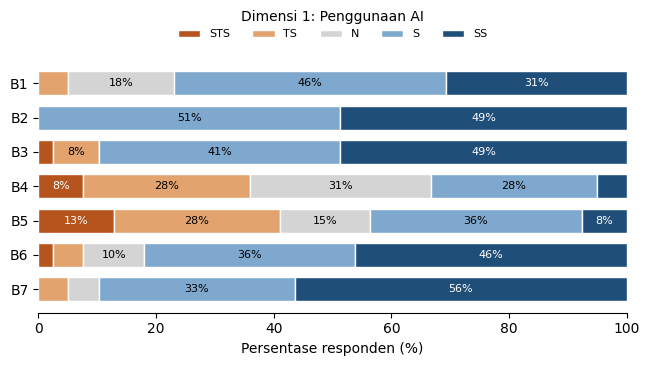

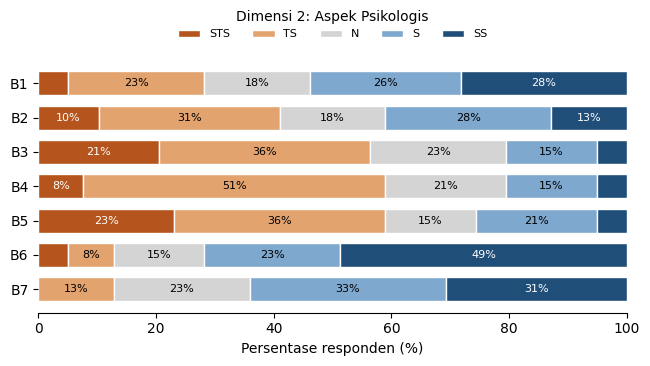

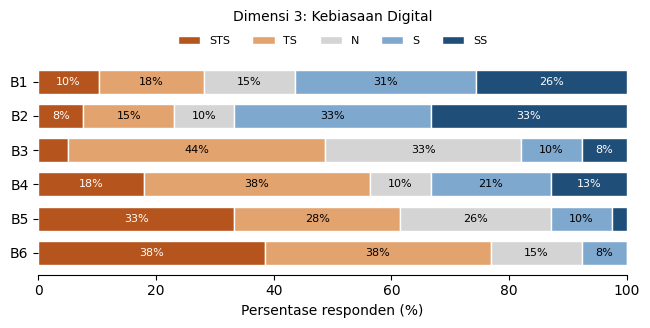

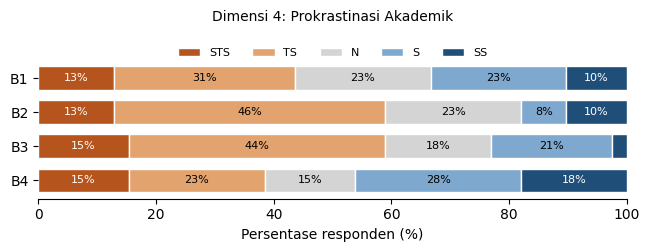

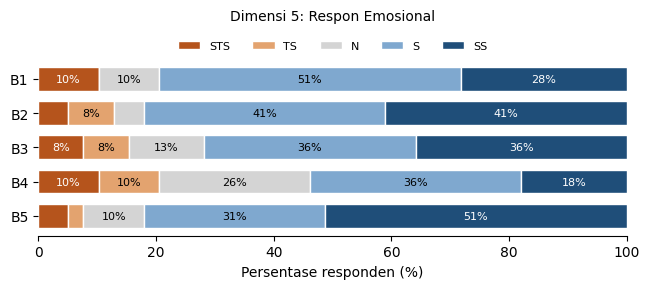

In [ ]:
for no, (nama, daftar) in enumerate(dimensi.items(), 1):
    persen = hitung_persen(num[daftar])
    gambar_komposisi(persen, f"Dimensi {no}: {nama}", f"grafik_dimensi{no}.png")

## Langkah 14 — Simpan dan unduh hasil

In [ ]:
nama_xlsx = "statistik_deskriptif_3TIA.xlsx"
tabel_deskriptif.to_excel(nama_xlsx, index=False)

if DI_COLAB:
    files.download(nama_xlsx)
    for no in range(1, len(dimensi) + 1):
        files.download(f"grafik_dimensi{no}.png")
else:
    print("Tersimpan di folder kerja:", nama_xlsx)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>